# LSTM one-month-ahead TWSA forecast with prediction intervals

Runs from the `LSTM_Water_Storage_Forecast` folder in Google Drive (`My Drive/DATA 255 Group Project/LSTM_Water_Storage_Forecast`). Results are written to `results/` and `models/lstm/` inside that folder.

**Runtime → Change runtime type → T4 GPU** is recommended (a few minutes). CPU also works but takes roughly an hour.

In [7]:
from google.colab import drive
drive.mount("/content/drive")

import os
FOLDER = "/content/drive/MyDrive/DATA 255 Group Project/LSTM_Water_Storage_Forecast"
os.chdir(FOLDER)

needed = ["scripts/lstm_forecast.py", "configs/lstm_config.yaml", "configs/grace_fo_config.yaml",
          "data/processed/grace_fo_train.nc", "data/processed/grace_fo_validation.nc",
          "data/processed/grace_fo_test.nc", "tests/test_lstm_forecast.py"]
missing = [f for f in needed if not os.path.exists(f)]
assert not missing, f"Missing in {FOLDER}: {missing}"
print("All input files found in", FOLDER)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
All input files found in /content/drive/MyDrive/DATA 255 Group Project/LSTM_Water_Storage_Forecast


In [8]:
!pip -q install netCDF4
import torch
print("PyTorch", torch.__version__, "| GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none (CPU)")

PyTorch 2.14.1+cu130 | GPU: Tesla T4


## Tests: leakage checks, metrics, interval calibration

In [9]:
!python -m unittest discover -s tests -p test_lstm_forecast.py -v

test_conformal_factor_reaches_nominal_coverage (test_lstm_forecast.LSTMForecastTests.test_conformal_factor_reaches_nominal_coverage) ... ok
test_inputs_precede_target_and_splits_do_not_mix (test_lstm_forecast.LSTMForecastTests.test_inputs_precede_target_and_splits_do_not_mix) ... ok
test_normalization_uses_training_months_only (test_lstm_forecast.LSTMForecastTests.test_normalization_uses_training_months_only) ... ok
test_score_matches_hand_computation (test_lstm_forecast.LSTMForecastTests.test_score_matches_hand_computation) ... /content/drive/MyDrive/DATA 255 Group Project/LSTM_Water_Storage_Forecast/scripts/lstm_forecast.py:122: RuntimeWarning: invalid value encountered in divide
  r_cell = (a * p).sum(0) / np.sqrt((a ** 2).sum(0) * (p ** 2).sum(0))
ok

----------------------------------------------------------------------
Ran 4 tests in 0.017s

OK


## Train the 5-member ensemble and evaluate on the 2024–2025 test months

In [10]:
!python scripts/lstm_forecast.py --config configs/lstm_config.yaml

Device cuda; 46325 cells; train targets 35 months, validation 12, test 24
  seed 0 epoch  1 train NLL 0.3465 val NLL 0.3145 val RMSE 2.974 cm (7s)
  seed 0 epoch  2 train NLL 0.2856 val NLL 0.2990 val RMSE 2.956 cm (6s)
  seed 0 epoch  3 train NLL 0.2553 val NLL 0.2878 val RMSE 2.933 cm (6s)
  seed 0 epoch  4 train NLL 0.2237 val NLL 0.2956 val RMSE 2.944 cm (7s)
  seed 0 epoch  5 train NLL 0.1939 val NLL 0.3355 val RMSE 2.968 cm (7s)
  seed 0 epoch  6 train NLL 0.1645 val NLL 0.3678 val RMSE 2.962 cm (7s)
  seed 1 epoch  1 train NLL 0.3446 val NLL 0.3096 val RMSE 2.967 cm (7s)
  seed 1 epoch  2 train NLL 0.2811 val NLL 0.3056 val RMSE 2.975 cm (7s)
  seed 1 epoch  3 train NLL 0.2524 val NLL 0.2995 val RMSE 2.971 cm (7s)
  seed 1 epoch  4 train NLL 0.2190 val NLL 0.3115 val RMSE 2.943 cm (7s)
  seed 1 epoch  5 train NLL 0.1843 val NLL 0.3295 val RMSE 2.950 cm (7s)
  seed 1 epoch  6 train NLL 0.1525 val NLL 0.3843 val RMSE 2.961 cm (7s)
  seed 2 epoch  1 train NLL 0.3478 val NLL 0.3063 

## Results

In [11]:
import json
import pandas as pd
from IPython.display import Image, display

m = "results/metrics/"
print("Test metrics (2024–2025)")
display(pd.read_csv(m + "lstm_test_metrics.csv").round(3))
print("RMSE (cm) by test year")
display(pd.read_csv(m + "lstm_test_metrics_by_year.csv").pivot(index="model", columns="year", values="rmse_cm").round(3))
print("RMSE (cm) by region")
display(pd.read_csv(m + "lstm_region_metrics.csv").pivot(index="region", columns="model", values="rmse_cm").round(2))
print("Prediction-interval coverage on the test months")
display(pd.read_csv(m + "lstm_interval_coverage.csv").round(3))
print(json.dumps(json.load(open(m + "lstm_uncertainty_summary.json")), indent=2))

Test metrics (2024–2025)


,model,mae_cm,rmse_cm,pearson_r,months,cells
0,LSTM (ensemble mean),2.262,2.871,0.826,24,46325
1,LSTM member 0,2.280,2.896,0.825,24,46325
2,LSTM member 1,2.274,2.884,0.826,24,46325
3,LSTM member 2,2.269,2.884,0.825,24,46325
4,LSTM member 3,2.276,2.886,0.824,24,46325
5,LSTM member 4,2.276,2.882,0.824,24,46325
6,Persistence,3.437,4.201,0.764,24,46325
7,Seasonal persistence,2.435,3.066,0.807,24,46325
8,Climatology,6.642,7.440,0.601,24,46325
9,"AR (p≤3, anomalies)",2.605,3.250,0.804,24,46325


RMSE (cm) by test year


year,2024,2025
model,,
"AR (p≤3, anomalies)",3.232,3.187
Climatology,7.211,7.265
LSTM (ensemble mean),2.934,2.721
Persistence,4.268,4.061
Seasonal persistence,3.010,3.054


RMSE (cm) by region


model,"AR (p≤3, anomalies)",Climatology,LSTM (ensemble mean),Persistence,Seasonal persistence
region,,,,,
Amazon,7.96,19.23,8.13,17.14,7.29
"Central Valley, California",3.82,7.68,3.45,5.01,3.77
East Africa (Lake Victoria),4.04,17.59,4.43,5.49,4.13
Middle East (Tigris–Euphrates),2.40,10.24,1.85,2.29,2.34
Northern Great Plains,2.17,5.70,2.21,2.53,2.21
Northern India,5.81,11.81,4.92,8.31,5.25


Prediction-interval coverage on the test months


,nominal,interval,multiplier,empirical_coverage,mean_width_cm
0,0.50,raw Gaussian,0.674,0.508,4.076
1,0.50,conformal-calibrated,0.652,0.493,3.939
2,0.80,raw Gaussian,1.282,0.802,7.744
3,0.80,conformal-calibrated,1.278,0.801,7.721
4,0.90,raw Gaussian,1.645,0.895,9.940
5,0.90,conformal-calibrated,1.666,0.900,10.066
6,0.95,raw Gaussian,1.960,0.943,11.844
7,0.95,conformal-calibrated,2.022,0.949,12.219


{
  "aleatoric_share_of_total_variance": 0.9889552688894262,
  "mean_sigma_cm": 3.021394726894727,
  "spearman_sigma_vs_abs_error": 0.5928226975116907,
  "conformal_factors_from_validation": {
    "0.5": 0.6518788933753967,
    "0.8": 1.277734398841858,
    "0.9": 1.6658469438552856,
    "0.95": 2.0220720767974854
  }
}


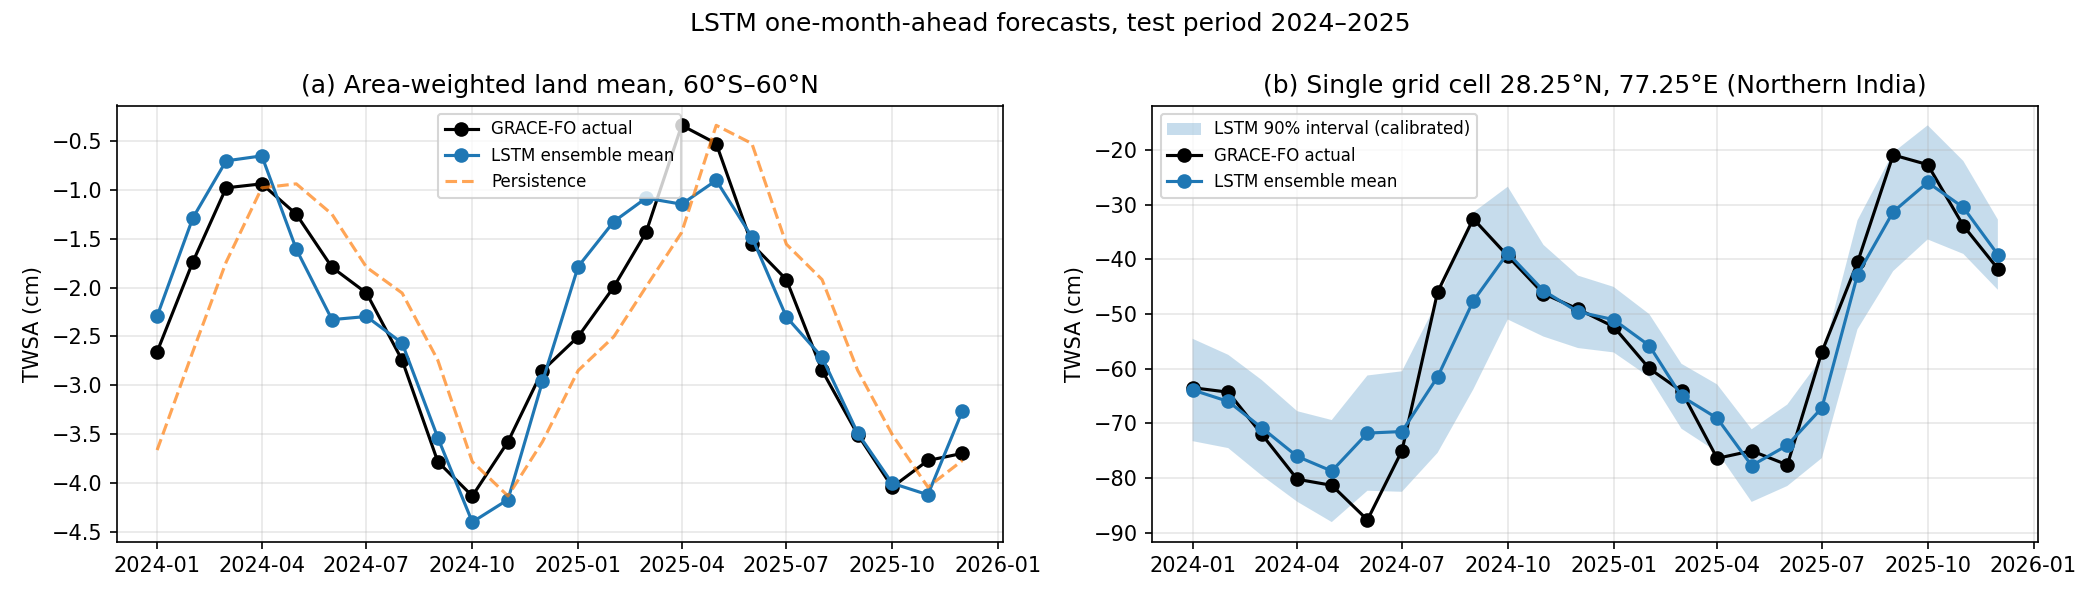

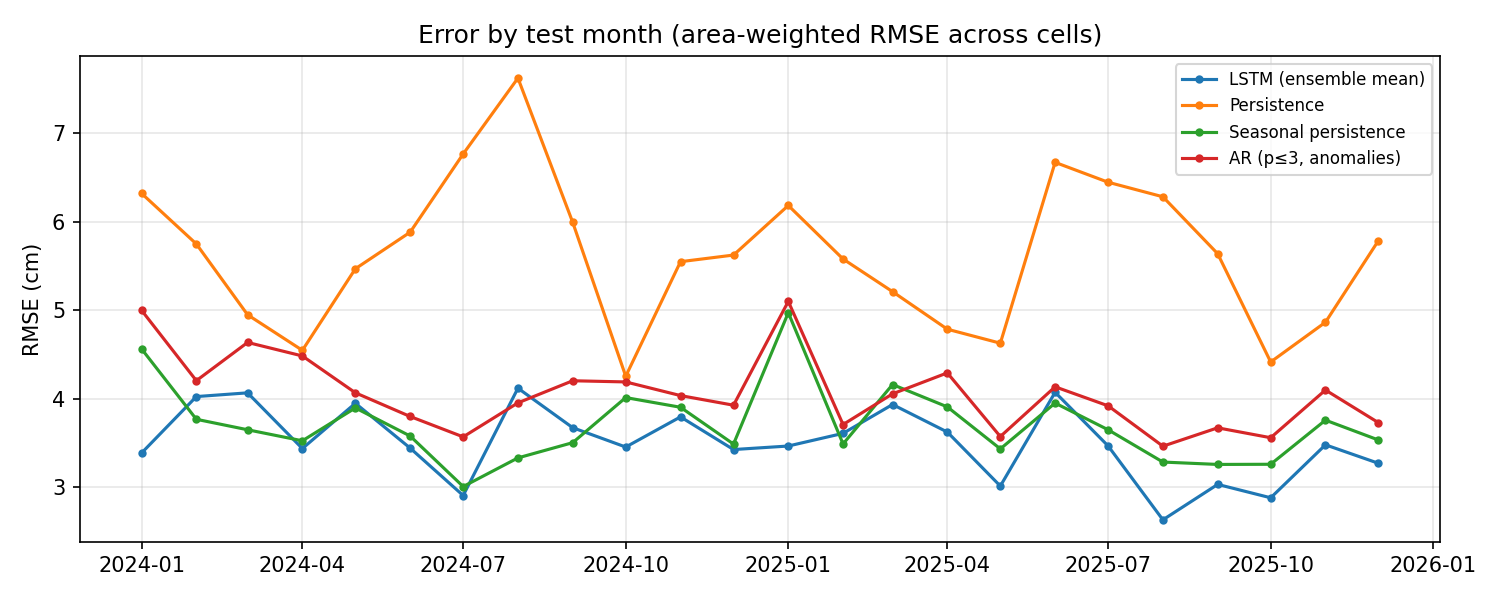

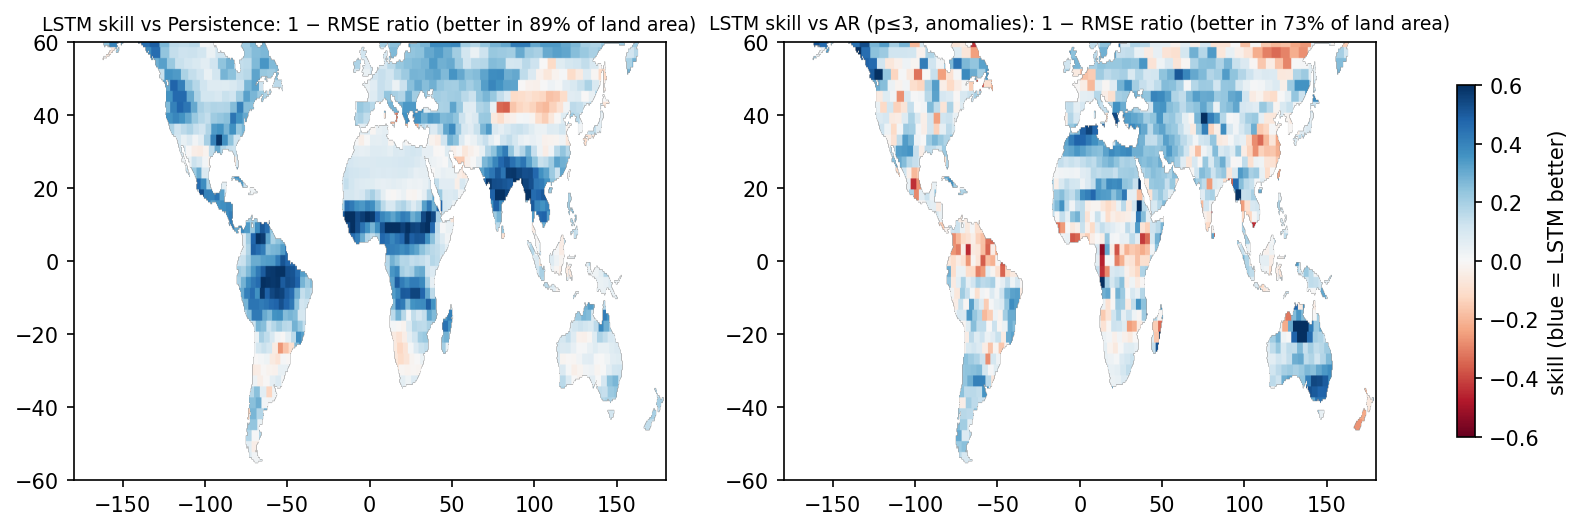

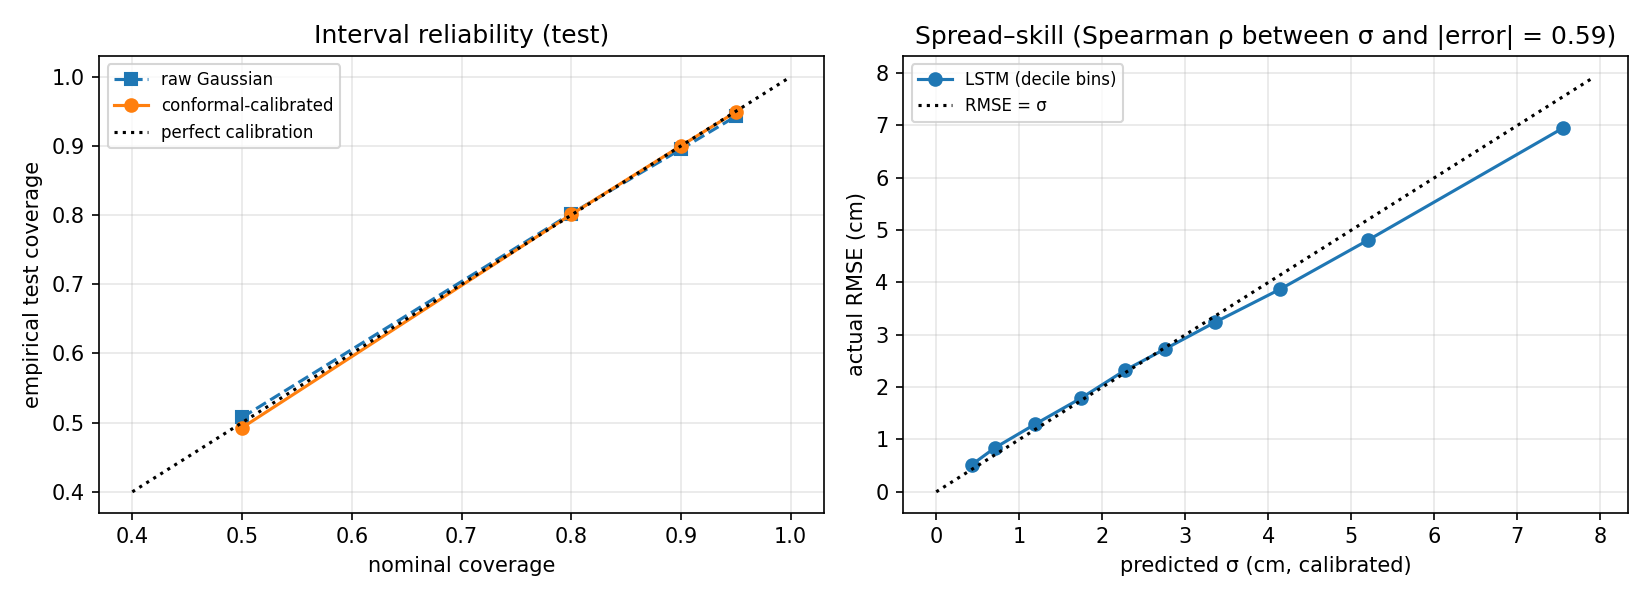

In [12]:
for name in ["test_actual_vs_predicted", "rmse_by_test_month", "skill_maps", "interval_reliability"]:
    display(Image(f"results/figures/lstm_{name}.png"))